# Prónostico (Forecasting)

### Carga de librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats
from sklearn.ensemble import GradientBoostingRegressor

### Carga de datos

In [2]:
df_biare = pd.read_csv("../Limpieza de datos (Practica 1)/biare_limpio_2021_2024.csv")

### Promedio por año de de la satisfacción con la vida e intervalo de confianza

Sacamos el promedio por año de la satisfacción con la vida y también sacamos el intervalo de confianza para poder comparar los años y conocer también la incertidumbre entre cada punto del pronostico.

In [3]:
#sacamos el intervalo de confianza con un 95% para el promedio de cada año
def ic95(serie):
    #95% de intervalo de confianza, grados de libertad, el total de personas -1, el centro del intervalo es el promedio y se saca el error estandar de la media
    return stats.t.interval(0.95, df=len(serie) - 1, loc=serie.mean(), scale=stats.sem(serie))

#se agrupa por año la satisfaccion con la vida y sacamos el conteo el promedio y la desviacion estandar
resumen_anual = df_biare.groupby('ANIO')['cb_P1'].agg(['count', 'mean', 'std'])
#aplicamos la funcion de intervalo de confianza a cada año
ic = df_biare.groupby('ANIO')['cb_P1'].apply(ic95)
#añadamis los intervalos de confianza al resumen anual
resumen_anual[['ic_inf', 'ic_sup']] = pd.DataFrame(ic.tolist(), index=ic.index)
print(resumen_anual.round(3))

      count   mean    std  ic_inf  ic_sup
ANIO                                     
2021   1969  8.287  1.686   8.213   8.362
2022   2013  8.277  1.612   8.207   8.348
2023   2038  8.344  1.494   8.279   8.409
2024   1999  8.597  1.749   8.520   8.674


### Gráfica de promedio de satisfacción con la vida por año y con intervalo de confianza

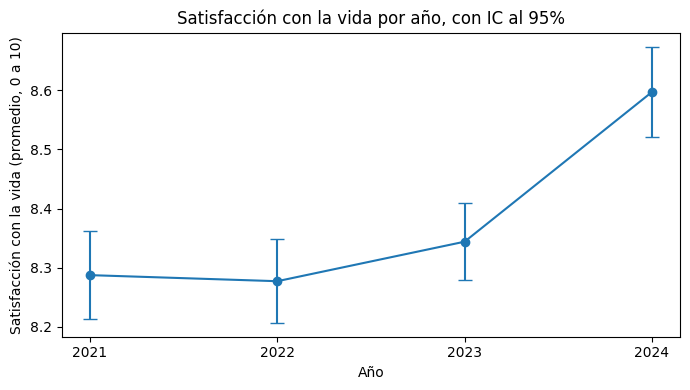

In [4]:
anios = resumen_anual.index
medias = resumen_anual['mean']
#intervalo de confianza inferior
error_inf = medias - resumen_anual['ic_inf']
#intervalo de confianza superior
error_sup = resumen_anual['ic_sup'] - medias

plt.figure(figsize=(7, 4))
plt.errorbar(anios, medias, yerr=[error_inf, error_sup], marker='o', capsize=5)
plt.xticks(anios)
plt.xlabel('Año')
plt.ylabel('Satisfacción con la vida (promedio, 0 a 10)')
plt.title('Satisfacción con la vida por año, con IC al 95%')
plt.tight_layout()
plt.show()

La satisfacción con la vida se mantuvo estable durante 2021 y 2022, mientras registro un pequeño aumento en 2023, en 2024 si alcanzó un aumento algo significativo de 2 puntos.

### Regresión lineal de la satisfacción con la vida por año

Hacemos una regresión lineal para saber cuanto cambia la satisfacción con la vida en cada año, con la pendiente vemos el cambio y con r al cuadrado vemos como la recta sigue los puntos.

In [5]:
#acomodamos por columna x, lo usaremos para predecir el año
X_anio = resumen_anual.index.values.reshape(-1, 1)
#el promedio de cada año lo usaremos como variable dependiente
y_media = resumen_anual['mean'].values

#creamos el modelo de regresion lineal y lo entrenamos con los datos de año y promedio de satisfacción con la vida
modelo= LinearRegression()
modelo.fit(X_anio, y_media)

#resultados
print("Pendiente:", round(modelo.coef_[0], 4))
print("R2:", round(modelo.score(X_anio, y_media), 3))

Pendiente: 0.0995
R2: 0.734


Del resultado podemos interpretar que por año la satisfacción con la vida sube aproximadamente 0.1 puntos por cada año, la recta nos explica cerca del 73% de los cambios entre el promedio de satisfacción con la vida entre cada año

### Proyectamos 2025 y 2026

In [6]:
anios_futuros = np.array([[2025], [2026]])
proyeccion = modelo.predict(anios_futuros)

for anio, valor in zip([2025, 2026], proyeccion):
    print(f"{anio}: {valor:.3f}")

2025: 8.625
2026: 8.725


El modelo lineal predice un promedio de satisfacción con la vida del año 2025 como 8.625 y del año 2026 como 8.725

### Gradient Boosting

Utilizamos otro modelo para poder comparar los resultados de nuestro modelo de regresión lineal, así mismo el gradient boosting lo que hace es entrenar muchos árboles de decisión pequeños, en donde el que sigue resuelve los errores que tuvo el anterior, al final la predicción es la suma de todos estos.

### Separamos los datos de entrenamiento de los de prueba

Usaremos como datos de prueba de 2021 a 2023 y de prueba los de 2024

In [7]:
#armamos una lista con todas las preguntas que nos ayudara a predecir la satisfaccion con la vida
predictores = [f'cb_P3_{i}' for i in range(1, 12)] + [f'cb_P5_{i}' for i in range(1, 13)]
#hacemos una tabla con solo las preguntas que nos serviran, los predictores, la satisfaccion con la vida y el año
datos_reg = df_biare[predictores + ['cb_P1', 'ANIO']].dropna()

#guardamos los datos de entrenamiento con los años 2021, 2022 y 2023
entrenamiento = datos_reg[datos_reg['ANIO'] <= 2023]
#guardamos los datos de prueba con el año 2024
prueba = datos_reg[datos_reg['ANIO'] == 2024]

#separamos los datos de entrenamiento y prueba en variables
X_train = entrenamiento[predictores]
y_train = entrenamiento['cb_P1']
X_test = prueba[predictores]
y_test = prueba['cb_P1']


### Gradient Boosting con corte temporal

In [8]:
#creamos el modelo gradient booster y usamos random_state para que los resultados sean el mismo
modelo_gb = GradientBoostingRegressor(random_state=42)
#entrenamos el modelo con los datos de entrenamiento
modelo_gb.fit(X_train, y_train)

#hacemos las predicciones con los datos de prueba
pred_gb = modelo_gb.predict(X_test)

#con los resultados que predijimos y los resultados reales de prueba, calculamos el error cuadratico medio
rmse_gb = mean_squared_error(y_test, pred_gb) ** 0.5
#calculamos el R2 score
r2_gb = r2_score(y_test, pred_gb)

#creamos una lista con el promedio de entrenamiento para cada persona de la prueba
base = np.full(len(y_test), y_train.mean())
#es el error del modelo base, que es predecir siempre el promedio de entrenamiento
rmse_base = mean_squared_error(y_test, base) ** 0.5

#resultados
print("RMSE del modelo:", round(rmse_gb, 3))
print("RMSE sin modelo (predecir siempre el promedio):", round(rmse_base, 3))
print("R2:", round(r2_gb, 3))
print("Promedio real 2024:", round(y_test.mean(), 3))
print("Promedio predicho 2024:", round(pred_gb.mean(), 3))

RMSE del modelo: 1.343
RMSE sin modelo (predecir siempre el promedio): 1.773
R2: 0.41
Promedio real 2024: 8.597
Promedio predicho 2024: 8.3


El error del modelo fue de 1.34 puntos, el cual es menor al de 1.77 que tendríamos si a todos les predijéramos el promedio, y el R cuadrada fue de 0.41, es decir que el modelo explica un poco menos de la mitad de las diferencias entre las personas. Aun así, se quedó corto con el promedio de 2024, ya que predijo 8.30 y el real fue 8.60, esto pasa porque en 2024 la gente contestó más alto que en los años anteriores y las preguntas del modelo no explican ese aumento.

### Regresión lineal con corte temporal

In [9]:
#creamos el modelo de regresion lineal
modelo_lineal = LinearRegression()
#entrenamos el modelo con los datos de entrenamiento
modelo_lineal.fit(X_train, y_train)

#hacemos las predicciones con los datos de prueba
pred_lineal = modelo_lineal.predict(X_test)

#con los resultados que predijimos y los resultados reales de prueba, calculamos el error cuadratico medio
rmse_lineal = mean_squared_error(y_test, pred_lineal) ** 0.5
#calculamos el R2 score
r2_lineal = r2_score(y_test, pred_lineal)

#resultados
print("RMSE del modelo:", round(rmse_lineal, 3))
print("R2:", round(r2_lineal, 3))
print("Promedio real 2024:", round(y_test.mean(), 3))
print("Promedio predicho 2024:", round(pred_lineal.mean(), 3))

RMSE del modelo: 1.315
R2: 0.434
Promedio real 2024: 8.597
Promedio predicho 2024: 8.321


El error del modelo fue de 1.32 puntos, el cual es menor al de 1.77 que tendríamos si a todos les predijéramos el promedio, y el R cuadrada fue de 0.43, es decir que el modelo explica un poco menos de la mitad de las diferencias entre las personas. Aun así, se quedó corto con el promedio de 2024, ya que predijo 8.32 y el real fue 8.60, esto pasa porque en 2024 la gente contestó más alto que en los años anteriores y las preguntas del modelo no explican ese aumento.

## Comparativa entre los modelos

In [10]:
#hacemos una comparacion usando como queda el promedio sin modelo, con regresion lineal y con gradient boosting
comparacion = pd.DataFrame({
    'modelo': ['Sin modelo', 'Regresión lineal', 'Gradient Boosting'],
    'RMSE': [rmse_base, rmse_lineal, rmse_gb],
    'R2': [r2_score(y_test, base), r2_lineal, r2_gb],
    'promedio_predicho': [y_train.mean(), pred_lineal.mean(), pred_gb.mean()]
})
comparacion['diferencia_vs_real'] = comparacion['promedio_predicho'] - y_test.mean()
print(comparacion.round(3))

              modelo   RMSE     R2  promedio_predicho  diferencia_vs_real
0         Sin modelo  1.773 -0.028              8.303              -0.294
1   Regresión lineal  1.315  0.434              8.321              -0.276
2  Gradient Boosting  1.343  0.410              8.300              -0.297


La regresión lineal salio un poco mejor, aunque la diferencia es muy pequeña, así que el modelo más complejo no aportó nada extra. Los dos se quedaron como 0.3 puntos abajo del promedio real de 2024, lo cual indica que ese aumento no se explica con las preguntas del modelo, y puede ser un cambio real o algo externo que no quedo registrado en las preguntas

### proyección a futuro comparado con los datos que tenemos

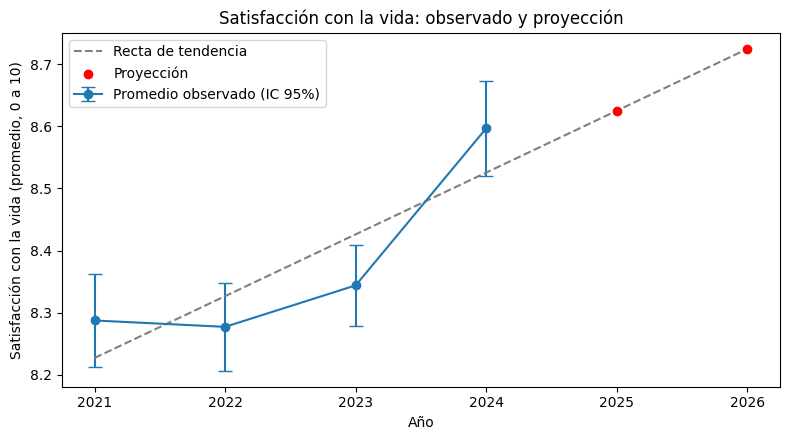

2025: 8.625
2026: 8.725


In [11]:
anios_futuros = np.array([[2025], [2026]])
proyeccion = modelo.predict(anios_futuros)

todos_anios = np.array([[2021], [2022], [2023], [2024], [2025], [2026]])

plt.figure(figsize=(8, 4.5))
plt.errorbar(anios, medias, yerr=[error_inf, error_sup], marker='o', capsize=5,
             label='Promedio observado (IC 95%)')
plt.plot(todos_anios, modelo.predict(todos_anios), linestyle='--', color='gray',
         label='Recta de tendencia')
plt.scatter([2025, 2026], proyeccion, color='red', zorder=3, label='Proyección')
plt.xticks([2021, 2022, 2023, 2024, 2025, 2026])
plt.xlabel('Año')
plt.ylabel('Satisfacción con la vida (promedio, 0 a 10)')
plt.title('Satisfacción con la vida: observado y proyección')
plt.legend()
plt.tight_layout()
plt.show()

for anio, valor in zip([2025, 2026], proyeccion):
    print(f"{anio}: {valor:.3f}")